In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import charge_trap_pot_model_4_layers as ctm4
import charge_trap_pot_model as ctm
import time


np.set_printoptions(threshold=sys.maxsize)

In [3]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [4]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Concatenate all points
YCT = (M/2)*AY

print('Y co-ordinate of charge trap =',YCT)

print('X co-ordinate of charge trap =', XCT )

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57


VCt = ModCT.charge_pot_lattice( XCT, YCT, ZCT, ZIM, ZQW)



Y co-ordinate of charge trap = 150.0
X co-ordinate of charge trap = 4150.0


In [5]:
NTOT*M

99600

In [6]:
VCt.shape

(99600, 99600)

In [7]:
type(VCt)

scipy.sparse._csr.csr_matrix

In [8]:
K = VCt.diagonal()
J = K.reshape(M,NTOT)

In [11]:
NSC*AX

4000

In [12]:
(NSC+NSM)*AX

4300

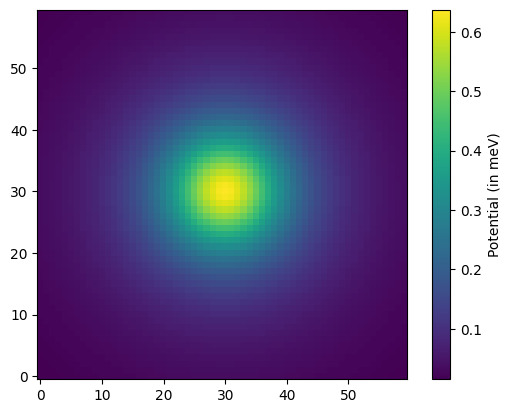

In [10]:
fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()


In [13]:
### 4 layer 

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418
Y co-ordinate of charge trap = 150.0
X co-ordinate of charge trap = 4150.0


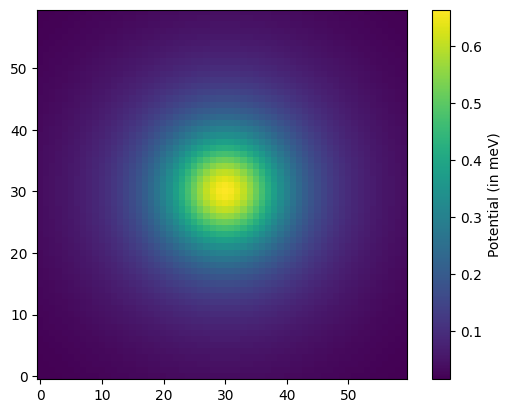

In [14]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT4 = ctm4.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48, t_ge=20)

#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Concatenate all points
YCT = (M/2)*AY

print('Y co-ordinate of charge trap =',YCT)

print('X co-ordinate of charge trap =', XCT )

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57


VCt4 = ModCT4.charge_pot_lattice( XCT, YCT, ZCT, ZIM, ZQW)



K4 = VCt4.diagonal()
J4 = K4.reshape(M,NTOT)

fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J4[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()


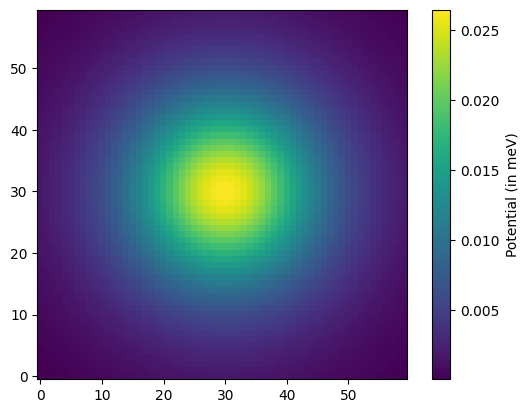

In [15]:

fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J4[:, NSC:NSC+NSM]-J[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()


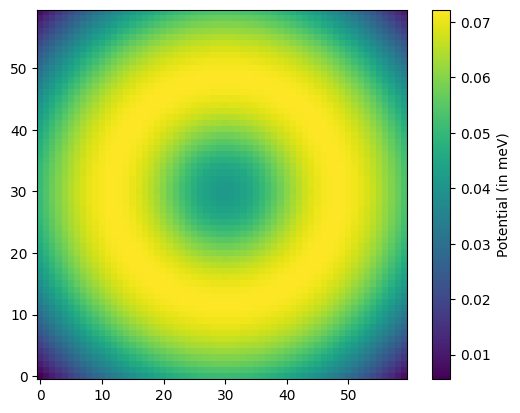

In [16]:
fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow((J4[:, NSC:NSC+NSM]-J[:, NSC:NSC+NSM])/J[:,NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()
